In [1]:
import sys

sys.path.append("../src")

import os
import numpy as np
import jax.numpy as jnp
from jax import random

import torch
from torch import optim

from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
import pandas as pd

from data_processing.load import load_and_preprocess_data
from data_processing.utils import (
    load_checkpoint,
    save_scaler_params,
    QuantileDistribution,
)
from models.model import WindPowerQuantile, model_mw_gamma

from numpyro.infer import Predictive
import arviz as az

### Load data and preprocess

- wind direction transformed from degree using sin and cos
- select one bid zone
- include UMM downtime data
- calculate capacity factor
- scale input features and meta data

Shapes:

- X: (timestamps, wind parks, features)
- Y: (timestamps)
- sites_meta: (wind parks, 1)


In [2]:
bid_zone = "ELSPOT NO1"

In [3]:
from operator import itemgetter

data = load_and_preprocess_data(bid_zone=bid_zone)
(
    X_train,
    X_test,
    Y_train_gen,
    Y_test_gen,
    Y_train_cf,
    Y_test_cf,
    Y_train_aval,
    Y_test_aval,
    sites_meta,
    feature_cols,
) = itemgetter(
    "X_train",
    "X_test",
    "Y_train_gen",
    "Y_test_gen",
    "Y_train_cf",
    "Y_test_cf",
    "Y_train_aval",
    "Y_test_aval",
    "sites_meta",
    "feature_cols",
)(
    data
)

/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:63: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


QUEUEING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?it…

PROCESSING TASKS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?, ?…

COLLECTING RESULTS | Calculating available capacity across full time range:   0%|          | 0/56298 [00:00<?,…

Preprocessing done. X_train shape: (19130, 6, 6)
Preprocessing done. X_test shape: (2161, 6, 6)


In [4]:
# Save scaler params ONCE (reused by all models for this bid zone)
save_scaler_params(
    scaler_params=data["scaler_params"],
    site_scaler_params=data["site_scaler_params"],
    bid_zone=bid_zone,
    split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
    dir_path="../checkpoints",
)

Saved scaler parameters for ELSPOT NO1: ../checkpoints/scaler_params_ELSPOT_NO1.pkl


'../checkpoints/scaler_params_ELSPOT_NO1.pkl'

### Deterministic Quantile NN

- Shared weights for all parks -> sum over parks
- Predicts Quantiles to approximate the full CDF
- Median acts as an anchor
- Distances to median for other quantiles
- All distances are generated cumulative by softplus -> positive -> ordering guaranteed and no crossing


In [5]:
X_train_tensor = torch.tensor(X_train)
Y_train_cf_tensor = torch.tensor(Y_train_cf)
Y_train_gen_tensor = torch.tensor(Y_train_gen)
X_test_tensor = torch.tensor(X_test)
Y_test_cf_tensor = torch.tensor(Y_test_cf)
sites_meta_tensor = torch.tensor(sites_meta, dtype=torch.float32)

In [6]:
_, num_windparks, num_features = X_train_tensor.shape

In [7]:
def quantile_loss(preds, target, quantiles=(0.025, 0.5, 0.975)):
    # preds: [T, Q], target: [T]
    diff = target.unsqueeze(-1) - preds  # [T, Q]
    quantiles = torch.tensor(quantiles).to(preds.device)  # [Q]

    # Pinball loss:
    loss = torch.maximum(quantiles * diff, (quantiles - 1) * diff)
    return loss.mean()

In [8]:
quantiles = np.linspace(0, 1, 51)
nn_model_quantile = WindPowerQuantile(num_features, quantiles)
optimizer = optim.Adam(nn_model_quantile.parameters(), lr=1e-3)
criterion = lambda preds, target: quantile_loss(preds, target, quantiles=quantiles)

losses = []

for step in range(3000):
    nn_model_quantile.train()
    optimizer.zero_grad()
    y_sum_pred = nn_model_quantile(X_train_tensor)

    loss = criterion(y_sum_pred, Y_train_gen_tensor)
    losses.append(loss.item())

    loss.backward()
    optimizer.step()

    if step % 250 == 0:
        print(f"Step {step:3d} | Loss: {loss.item():.4f}")

Step   0 | Loss: 51.6176
Step 250 | Loss: 19.8822
Step 500 | Loss: 14.7121
Step 750 | Loss: 13.4652
Step 1000 | Loss: 12.9771
Step 1250 | Loss: 12.5148
Step 1500 | Loss: 12.1502
Step 1750 | Loss: 11.9484
Step 2000 | Loss: 11.7926
Step 2250 | Loss: 11.6636
Step 2500 | Loss: 11.5681
Step 2750 | Loss: 11.4853


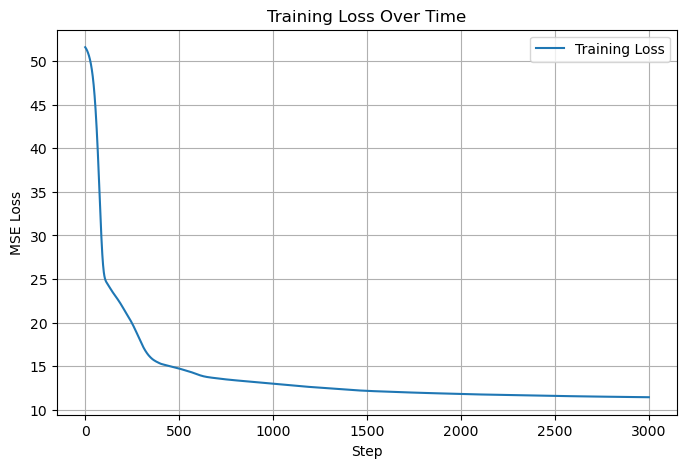

In [9]:
plt.figure(figsize=(8, 5))
plt.plot(losses, label="Training Loss")
plt.xlabel("Step")
plt.ylabel("MSE Loss")
plt.title("Training Loss Over Time")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
median_idx = (quantiles == 0.5).nonzero()[0].item()

nn_model_quantile.eval()
with torch.no_grad():
    y_sum_pred = nn_model_quantile(X_test_tensor)

Y_pred = y_sum_pred.numpy()

mse = mean_squared_error(Y_test_gen, Y_pred[:, median_idx])
rmse = jnp.sqrt(mse)


print(f"Evaluation metrics:")
print(f"RMSE: {rmse:.2f} MW")

Evaluation metrics:
RMSE: 65.19 MW


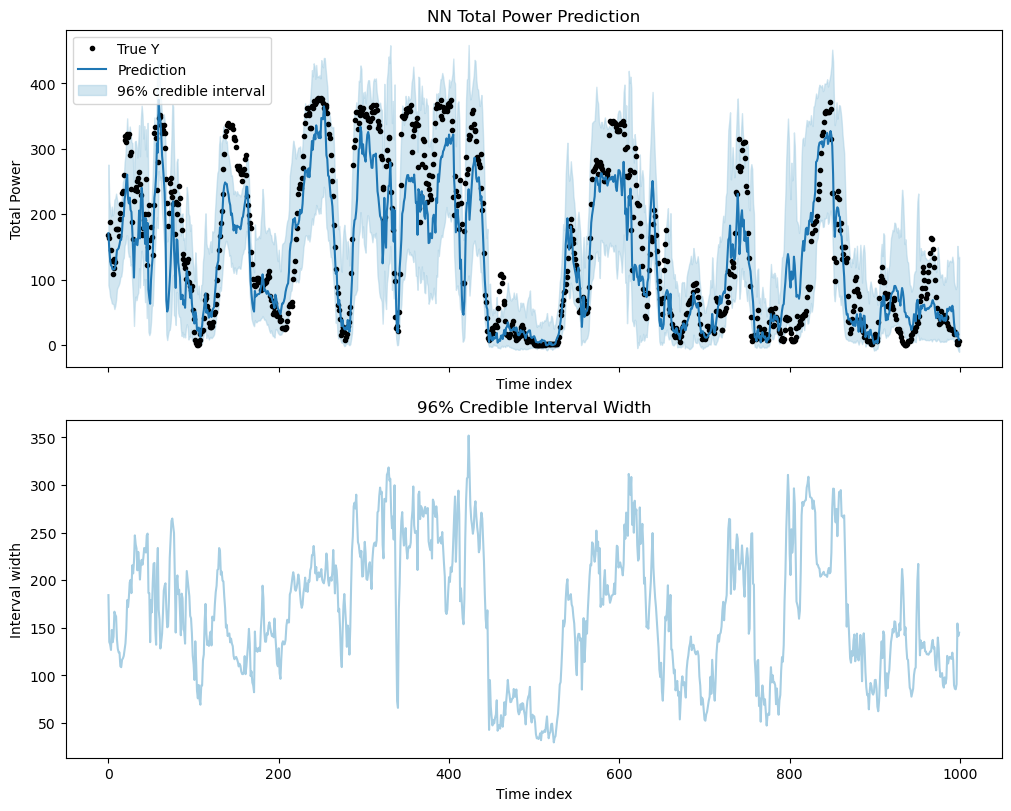

In [11]:
# Plot
median_idx = (quantiles == 0.5).nonzero()[0].item()
q02_idx = (quantiles == 0.02).nonzero()[0].item()
q98_idx = (quantiles == 0.98).nonzero()[0].item()

n_plot = 1000
fig, axes = plt.subplots(figsize=(10, 8), nrows=2, sharex=True, constrained_layout=True)
ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="True Y")
ax.plot(Y_pred[:n_plot, median_idx], color="C0", label="Prediction")
ax.fill_between(
    range(n_plot),
    Y_pred[:n_plot, q02_idx],
    Y_pred[:n_plot, q98_idx],
    color="#A6CEE3",
    alpha=0.5,
    label="96% credible interval",
)
ax.set(xlabel="Time index", ylabel="Total Power", title="NN Total Power Prediction")
ax.legend()

ax2 = axes[1]
ax2.plot(
    range(n_plot),
    Y_pred[:n_plot, q98_idx] - Y_pred[:n_plot, q02_idx],
    color="#A6CEE3",
)
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="96% Credible Interval Width",
)
plt.show()

### Sanity checks


In [35]:
print("Negative values for predictions: ", np.sum(Y_pred < 0).item())

Negative values for predictions:  3425


In [36]:
Y_pred.shape

(2161, 51)

In [12]:
violations = np.mean(np.diff(Y_pred, axis=1) < 0)
print("Fraction of quantile crossing violations:", violations)

Fraction of quantile crossing violations: 0.0


In [13]:
emp_cov = [np.mean(Y_test_gen <= Y_pred[:, i]) for i in range(len(quantiles))]

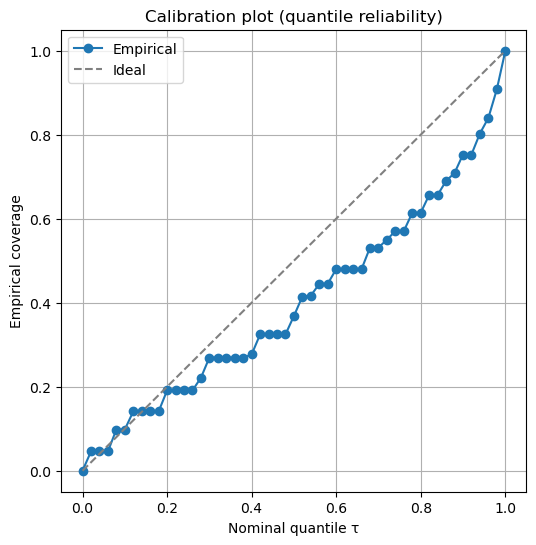

In [14]:
plt.figure(figsize=(6, 6))
plt.plot(quantiles, emp_cov, "o-", label="Empirical")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Ideal")
plt.xlabel("Nominal quantile τ")
plt.ylabel("Empirical coverage")
plt.title("Calibration plot (quantile reliability)")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
q_low = Y_pred[:, q02_idx]
q_high = Y_pred[:, q98_idx]
inside = np.mean((Y_test_gen >= q_low) & (Y_test_gen <= q_high))
print("96% interval empirical coverage:", inside)

96% interval empirical coverage: 0.8621008792225822


In [16]:
coverages = []

for j, tau in enumerate([0.02, 0.5, 0.98]):
    idx = (quantiles == tau).nonzero()[0].item()
    cov = np.mean(Y_test_gen <= Y_pred[:, idx])
    coverages.append(cov)
    print(f"Quantile tau={tau:.3f}, empirical P(Y <= q_tau) = {cov:.3f}")

Quantile tau=0.020, empirical P(Y <= q_tau) = 0.046
Quantile tau=0.500, empirical P(Y <= q_tau) = 0.368
Quantile tau=0.980, empirical P(Y <= q_tau) = 0.908


### Approximation of CDF and PDF

- with enough quantiles, the CDF can be approximated empirically


In [17]:
taus = np.linspace(0, 1, 51)

dist = QuantileDistribution(
    taus, np.mean(Y_pred, axis=0)
)  # use t=10, Y_pred[t] instead of mean for a single timestep


hdis = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).hdi(cred_mass=0.95, n_samples=5000)
        for i in range(Y_test_gen.shape[0])
    ]
)

q025_qr = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).icdf(0.025)
        for i in range(Y_test_gen.shape[0])
    ]
)
q975_qr = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).icdf(0.975)
        for i in range(Y_test_gen.shape[0])
    ]
)
medians = np.array(
    [
        QuantileDistribution(taus, Y_pred[i]).icdf(0.5)
        for i in range(Y_test_gen.shape[0])
    ]
)

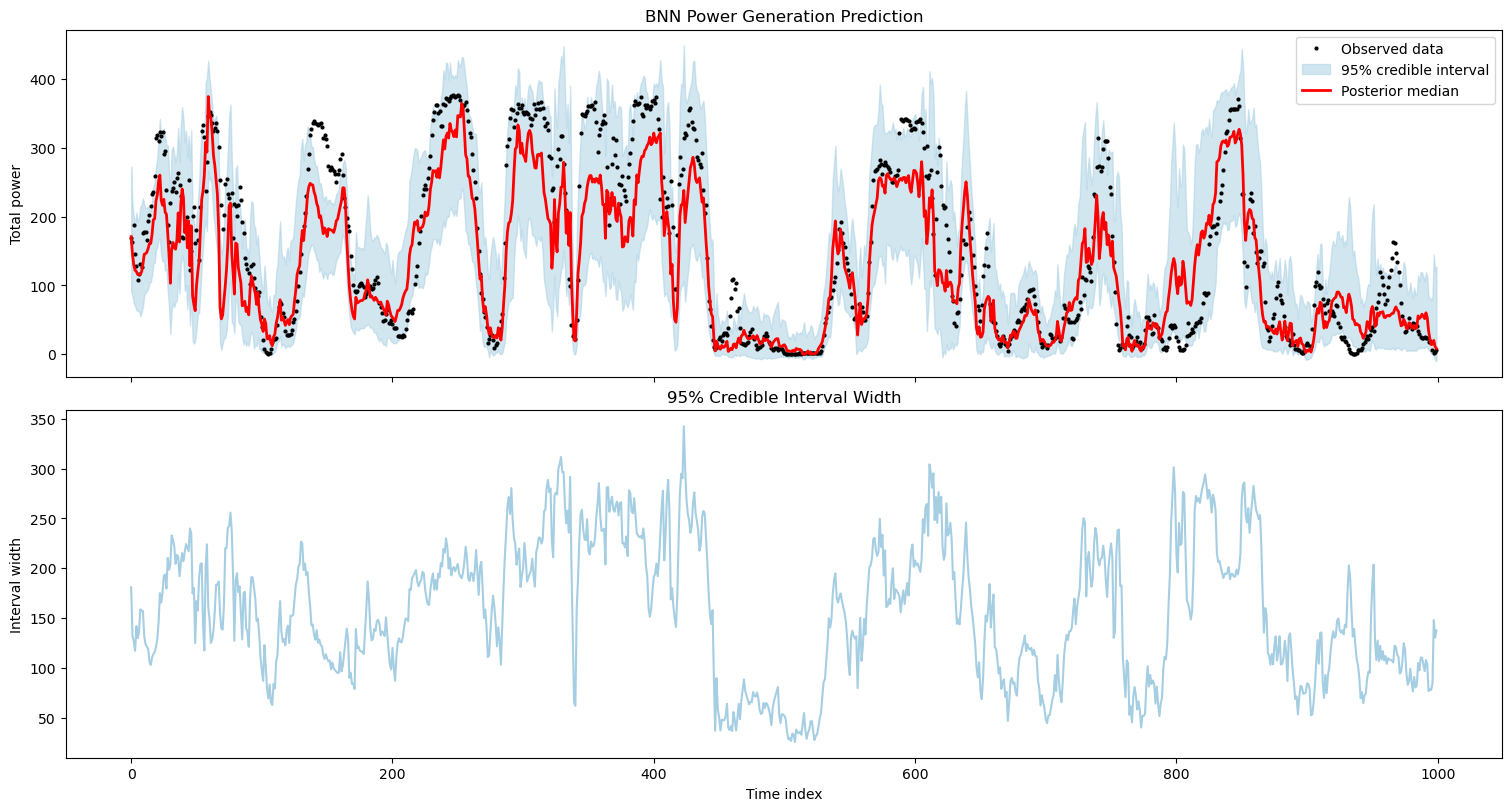

In [18]:
# Uses sampled HDI (QuantileDistribution class)
n_plot = 1000

fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)

ax.fill_between(
    np.arange(n_plot),
    hdis[:n_plot, 0],
    hdis[:n_plot, 1],
    color="#A6CEE3",
    alpha=0.5,
    label="95% credible interval",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()


# Compute interval width
width = hdis[:n_plot, 1] - hdis[:n_plot, 0]
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)

plt.show()

### Load BNN to compare Quantiles


In [19]:
state_ckp = load_checkpoint(file_name="model_mw_gamma_2025-11-13_10-56-50_gen")
samples_gamma = state_ckp["samples"]
args = state_ckp["args"]
rng_key_ckp = state_ckp["rng_key"]
rng_key, rng_key_predict = random.split(rng_key_ckp)

predictive = Predictive(model_mw_gamma, samples_gamma)(rng_key_predict, X_test)

preds = predictive["Y"]
mu = predictive["mu"]
alpha = predictive["alpha"]

preds_mean = preds.mean(axis=0)
median_bnn = np.percentile(preds, 50, axis=0)
q025_bnn = np.percentile(preds, 2.5, axis=0)
q975_bnn = np.percentile(preds, 97.5, axis=0)
hdi_bnn = az.hdi(np.expand_dims(preds, axis=0), hdi_prob=0.95)

q_bnn = np.array([])

Loading specified checkpoint: ../checkpoints/model_mw_gamma_2025-11-13_10-56-50_gen.pkl


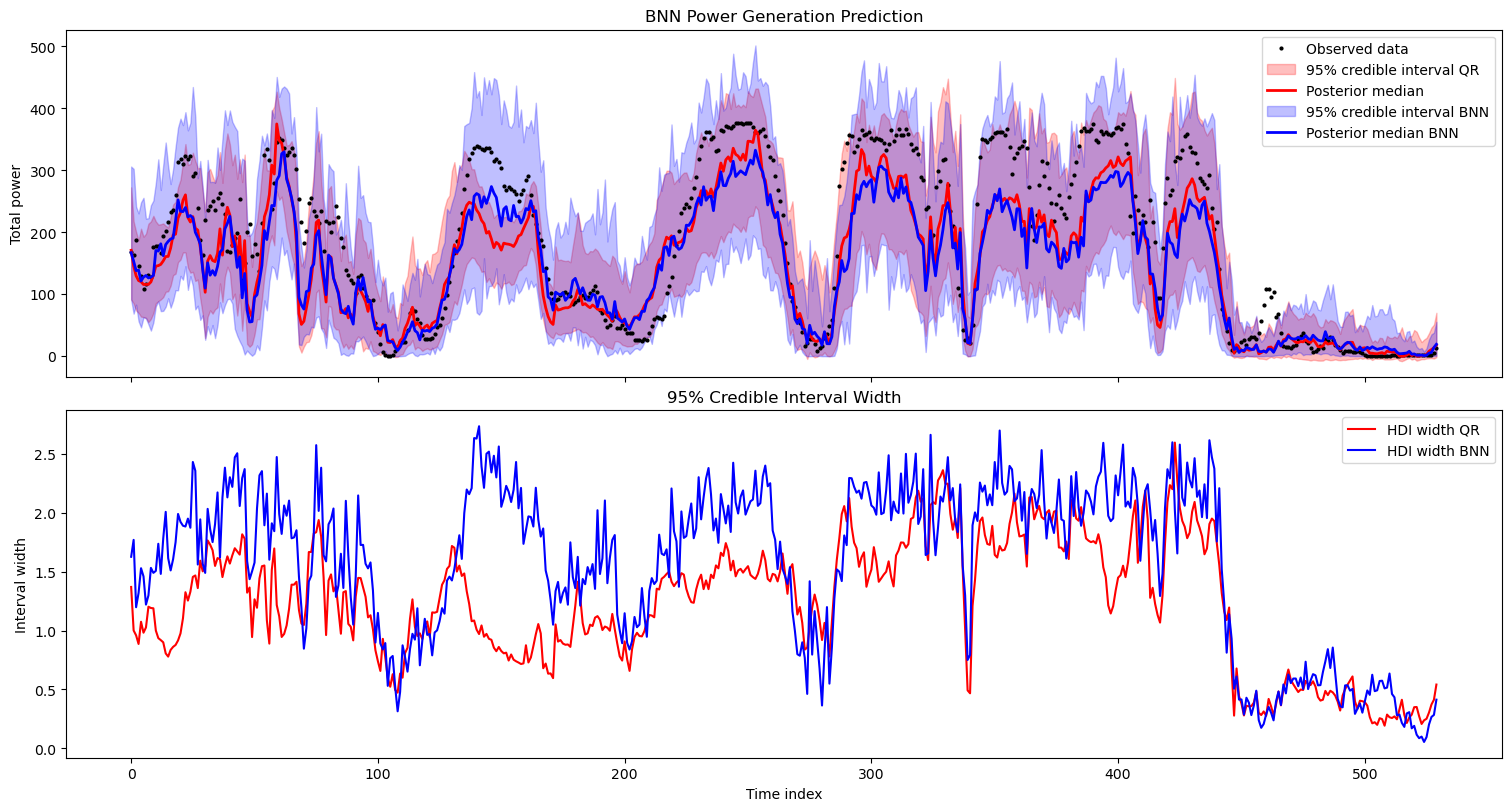

In [56]:
# HDI CI
n_plot = 530

fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)

ax.fill_between(
    np.arange(n_plot),
    hdis[:n_plot, 0],
    hdis[:n_plot, 1],
    color="red",
    alpha=0.25,
    label="95% credible interval QR",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()

ax.fill_between(
    np.arange(n_plot),
    hdi_bnn[:n_plot, 0],
    hdi_bnn[:n_plot, 1],
    color="blue",
    alpha=0.25,
    label="95% credible interval BNN",
)

ax.plot(median_bnn[:n_plot], color="blue", label="Posterior median BNN", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()

normalization_factor = np.median(Y_test_gen)
# Compute interval width
width = hdis[:n_plot, 1] - hdis[:n_plot, 0]
width_bnn = hdi_bnn[:n_plot, 1] - hdi_bnn[:n_plot, 0]
ax2 = axes[1]
ax2.plot(width / normalization_factor, color="red", label="HDI width QR")
ax2.plot(width_bnn / normalization_factor, color="blue", label="HDI width BNN")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)
ax2.legend()


plt.show()

In [ ]:
width[500:530] / medians[500:530]

array([   3.79097981,    4.60852696,    7.05766751,    5.73873883,
          6.93789731,    6.63413635,    6.77004765,    5.68131987,
          6.52178955,    4.56517496,    4.86174644,    4.85482632,
          5.30406671,    6.07833083,  693.71139254, -659.48914033,
        120.69509976,   15.76628204,    7.42423881,   39.36701556,
         13.91577987,  874.77107808,  146.06710677,   32.33869086,
         26.46683568,   11.63401193,    5.00536711,    4.57586161,
          3.96746398,    3.96177026])

In [51]:
medians[500:530]

array([13.69232941, 10.40715694,  4.98146296,  4.91215086,  4.24014568,
        3.99524117,  5.00735569,  5.7946353 ,  3.91680646,  8.31832886,
        7.20168924,  7.02821159,  6.77789164,  5.38089323,  0.062887  ,
       -0.08274789,  0.31133035,  1.81346488,  4.67974234,  0.96237165,
        3.3243897 ,  0.05312924,  0.24765138,  0.84962785,  1.1929028 ,
        2.86254787,  8.04342747, 10.7675457 , 13.76081753, 18.07542801])

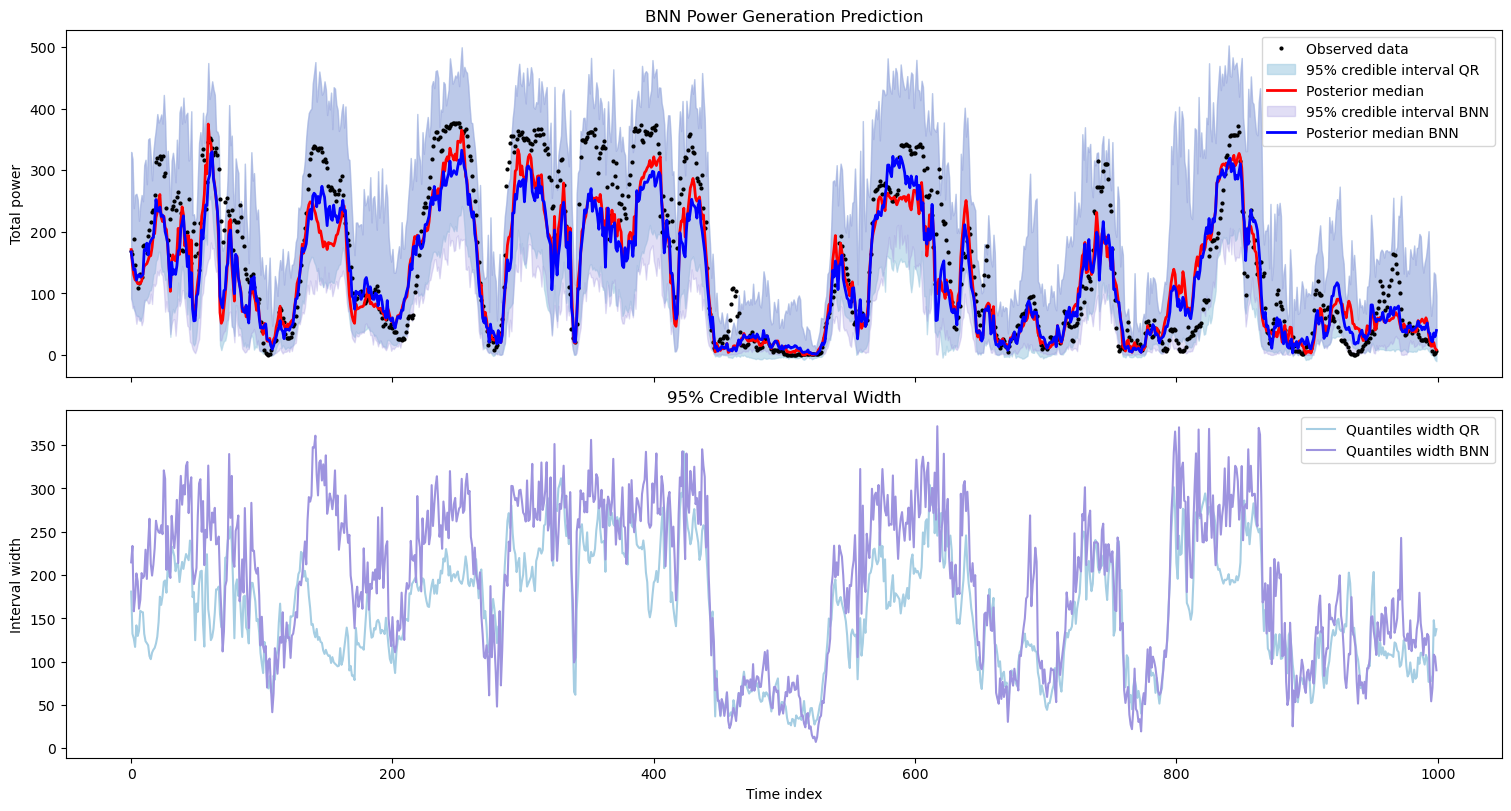

In [ ]:
# CI based on quantiles
n_plot = 1000

fig, axes = plt.subplots(nrows=2, figsize=(15, 8), sharex=True, constrained_layout=True)

ax = axes[0]
ax.plot(Y_test_gen[:n_plot], ".", color="black", label="Observed data", markersize=4)

ax.fill_between(
    np.arange(n_plot),
    q025_qr[:n_plot],
    q975_bnn[:n_plot],
    color="#A6CEE3",
    alpha=0.6,
    label="95% credible interval QR",
)

ax.plot(medians[:n_plot], color="red", label="Posterior median", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()

ax.fill_between(
    np.arange(n_plot),
    q025_bnn[:n_plot],
    q975_bnn[:n_plot],
    color="#9E94DF",
    alpha=0.3,
    label="95% credible interval BNN",
)

ax.plot(median_bnn[:n_plot], color="blue", label="Posterior median BNN", lw=2)

ax.set(
    ylabel="Total power",
    title="BNN Power Generation Prediction",
)
ax.legend()


# Compute interval width
width = hdis[:n_plot, 1] - hdis[:n_plot, 0]
width_bnn = hdi_bnn[:n_plot, 1] - hdi_bnn[:n_plot, 0]
ax2 = axes[1]
ax2.plot(width, color="#A6CEE3", label="Quantiles width QR")
ax2.plot(width_bnn, color="#9E94DF", label="Quantiles width BNN")
ax2.set(
    xlabel="Time index",
    ylabel="Interval width",
    title="95% Credible Interval Width",
)
ax2.legend()


plt.show()

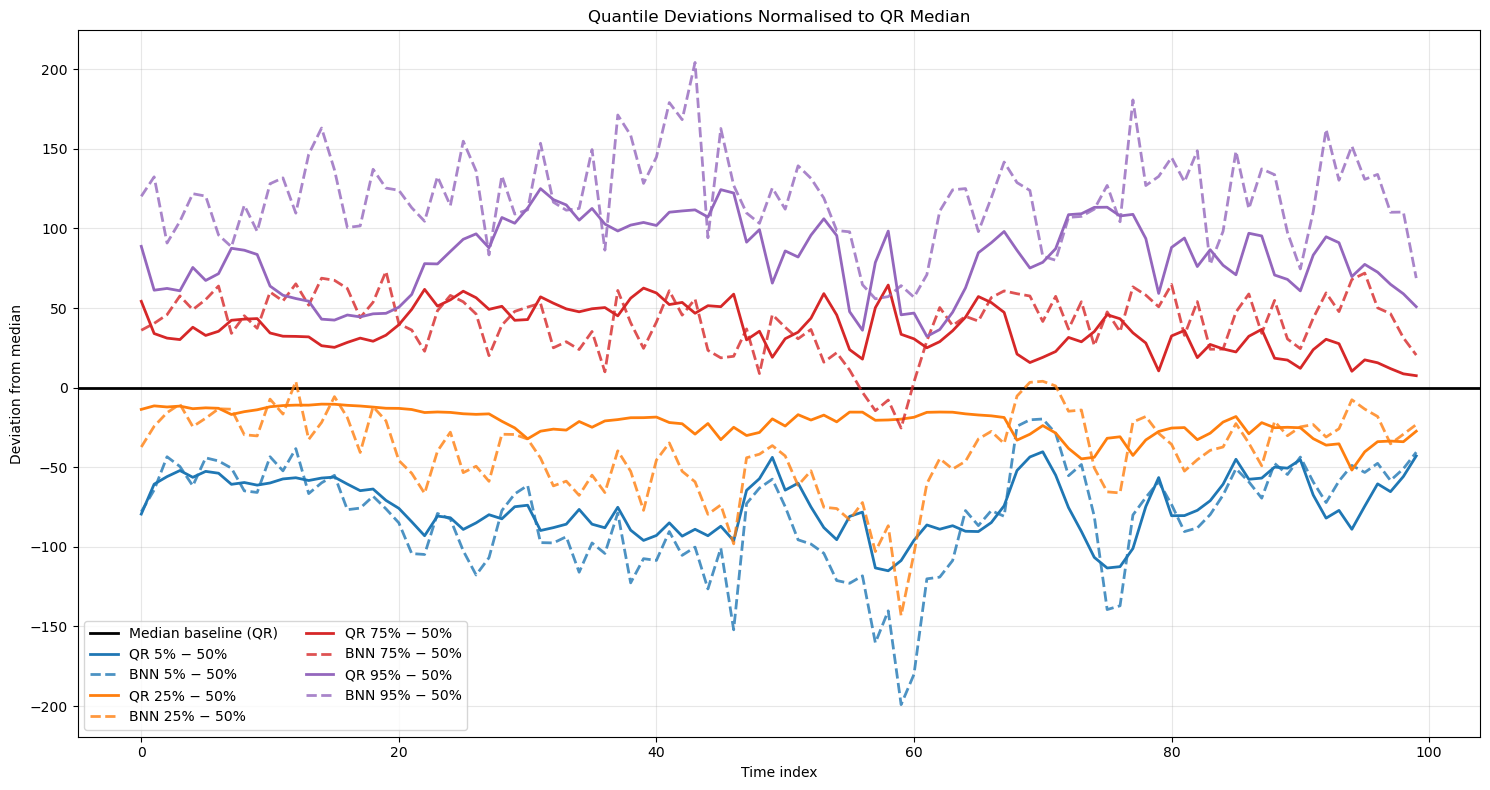

In [22]:
quantiles_plot = [0.05, 0.25, 0.50, 0.75, 0.95]
n_plot = 100

# Compute QR quantiles
q_qr = []
for q in quantiles_plot:
    q_qr.append(
        [
            QuantileDistribution(taus, Y_pred[i]).icdf(q)
            for i in range(Y_test_gen.shape[0])
        ]
    )
q_qr = np.array(q_qr)  # shape (5, N)
differences_qr = q_qr - q_qr[2]  # subtract QR median

# Compute BNN quantiles
q_bnn = []
for q in quantiles_plot:
    q_bnn.append(np.percentile(preds, q * 100, axis=0))
q_bnn = np.array(q_bnn)  # shape (5, N)

# Normalise BNN to the QR median
differences_bnn = q_bnn - q_qr[2]

# Display only first n_plot timesteps

Q, N = differences_qr.shape
n_plot = min(n_plot, N)
t = np.arange(n_plot)

plt.figure(figsize=(15, 8))

plt.axhline(0, color="black", lw=2, label="Median baseline (QR)")

colors = ["C0", "C1", "C2", "C3", "C4"]

for i, q in enumerate(quantiles_plot):
    if q == 0.50:
        continue  # skip median

    # QR model = solid
    plt.plot(
        t,
        differences_qr[i, :n_plot],
        lw=2,
        color=colors[i],
        label=f"QR {int(q*100)}% − 50%",
    )

    # BNN model = dashed
    plt.plot(
        t,
        differences_bnn[i, :n_plot],
        "--",
        lw=2,
        color=colors[i],
        alpha=0.8,
        label=f"BNN {int(q*100)}% − 50%",
    )

plt.title("Quantile Deviations Normalised to QR Median")
plt.xlabel("Time index")
plt.ylabel("Deviation from median")
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

Variances of quantiles:
Quantile 0.03: Variance = 0.059897
Quantile 0.05: Variance = 0.042625
Quantile 0.25: Variance = 0.018536
Quantile 0.50: Variance = 0.015528
Quantile 0.75: Variance = 0.017827
Quantile 0.95: Variance = 0.039077
Quantile 0.97: Variance = 0.057538


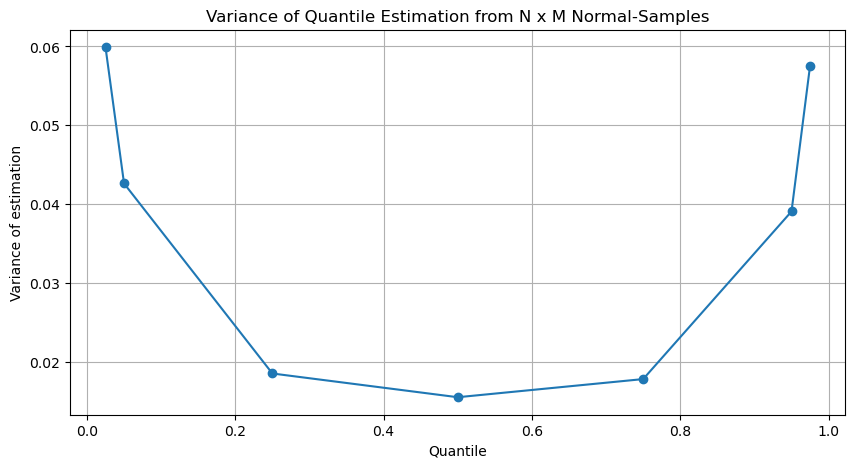

In [100]:
N = 1000  # N experiments
M = 100  # Samples per experiment

# Quantiles
quantiles = [0.025, 0.05, 0.25, 0.5, 0.75, 0.95, 0.975]


Q = np.zeros((N, len(quantiles)))

# draw N times M samples and estimate quantiles
for i in range(N):
    samples = np.random.normal(loc=0, scale=1, size=M)
    Q[i] = np.quantile(samples, quantiles)

# Variance of quantile estimation
variances = Q.var(axis=0)

print("Variances of quantiles:")
for q, v in zip(quantiles, variances):
    print(f"Quantile {q:.2f}: Variance = {v:.6f}")

# Plot
plt.figure(figsize=(10, 5))
plt.plot(quantiles, variances, marker="o")
plt.title("Variance of Quantile Estimation from N x M Normal-Samples")
plt.xlabel("Quantile")
plt.ylabel("Variance of estimation")
plt.grid(True)
plt.show()